# 1. Preparação do Ambiente e Descompactação dos Dados
Nesta etapa, importamos as bibliotecas necessárias para manipulação de dados em tabelas (Pandas) e dados espaciais (GeoPandas). Em seguida, descompactamos o repositório oficial que contém o shapefile da grade e a planilha de alagamentos.

In [ ]:
# Instalar a biblioteca espacial (caso o Colab não a tenha por padrão)
!pip install geopandas

import zipfile
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

# Descompactar o arquivo ZIP
zip_path = "floods_saopaulo-main.zip"
extract_dir = "/content/floods_data"

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_dir)

print("Arquivos descompactados com sucesso!")

Arquivos descompactados com sucesso!


# 2. Processamento dos Dados Meteorológicos (INMET)
Além da chuva diária, agora agregamos por dia diversas variáveis horárias do INMET que
têm relação física com enchentes: pico de intensidade da chuva em 1h, nº de horas de
chuva, chuva no período convectivo da tarde/noite, pressão mínima e amplitude de pressão,
umidade, temperatura (máxima e amplitude), rajada de vento e radiação global. As janelas
deslizantes de saturação do solo (3 e 7 dias) são calculadas antes de filtrar os dias secos.


In [ ]:
# ---- Carregar INMET ----
inmet_file = "INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2019_A_31-12-2019.CSV"
df_inmet = pd.read_csv(inmet_file, sep=';', encoding='latin-1', skiprows=8, decimal=',')
df_inmet['Data'] = pd.to_datetime(df_inmet['Data'])

# Localiza colunas por palavra-chave (robusto a acentos/símbolos no cabeçalho)
def col(chave):
    for c in df_inmet.columns:
        if chave.lower() in c.lower():
            return c
    return None

col_chuva   = col('PRECIPITA')
col_pressao = col('PRESSAO ATMOSFERICA AO NIVEL')
col_rad     = col('RADIACAO GLOBAL')
col_temp    = col('TEMPERATURA DO AR - BULBO SECO')
col_orv     = col('TEMPERATURA DO PONTO DE ORVALHO')
col_umid    = col('UMIDADE RELATIVA DO AR, HORARIA')
col_raj     = col('VENTO, RAJADA MAXIMA')
col_vel     = col('VENTO, VELOCIDADE HORARIA')

df_inmet[col_chuva] = df_inmet[col_chuva].fillna(0)

# Hora local (SP = UTC-3) para isolar a janela convectiva da tarde/noite
df_inmet['hora_utc']   = df_inmet['Hora UTC'].astype(str).str.extract(r'(\d{2})').astype(int)
df_inmet['hora_local'] = (df_inmet['hora_utc'] - 3) % 24

g = df_inmet.groupby('Data')

df_clima = pd.DataFrame({
    'chuva_dia'    : g[col_chuva].sum(),                       # total diário
    'chuva_max_h'  : g[col_chuva].max(),                       # pico de intensidade em 1h
    'horas_chuva'  : g[col_chuva].apply(lambda s: (s > 0).sum()),
    'pressao_min'  : g[col_pressao].min(),
    'pressao_amp'  : g[col_pressao].max() - g[col_pressao].min(),
    'umidade_med'  : g[col_umid].mean(),
    'umidade_max'  : g[col_umid].max(),
    'temp_med'     : g[col_temp].mean(),
    'temp_max'     : g[col_temp].max(),
    'temp_amp'     : g[col_temp].max() - g[col_temp].min(),
    'orvalho_med'  : g[col_orv].mean(),
    'rajada_max'   : g[col_raj].max(),
    'vento_med'    : g[col_vel].mean(),
    'radiacao_sum' : g[col_rad].sum(),
}).reset_index()

# Chuva da tarde/noite (12h–23h local): janela convectiva típica de São Paulo
chuva_tarde = (df_inmet[df_inmet['hora_local'].between(12, 23)]
               .groupby('Data')[col_chuva].sum()
               .rename('chuva_tarde'))
df_clima = df_clima.merge(chuva_tarde, on='Data', how='left')

# Janelas de saturação do solo (ANTES de filtrar dias secos)
df_clima = df_clima.sort_values('Data').reset_index(drop=True)
df_clima['chuva_acum_3d'] = df_clima['chuva_dia'].rolling(window=3, min_periods=1).sum()
df_clima['chuva_acum_7d'] = df_clima['chuva_dia'].rolling(window=7, min_periods=1).sum()

# Preenche eventuais faltantes (radiação à noite, etc.) e filtra só dias com chuva
df_clima = df_clima.fillna(df_clima.median(numeric_only=True))
df_clima = df_clima[df_clima['chuva_dia'] > 0]

print(f"Dias com chuva em 2019: {len(df_clima)}")
print(f"Variáveis meteorológicas criadas: {[c for c in df_clima.columns if c != 'Data']}")
df_clima.head()


Dias com chuva em 2019: 151
Variáveis meteorológicas criadas: ['chuva_dia', 'chuva_max_h', 'horas_chuva', 'pressao_min', 'pressao_amp', 'umidade_med', 'umidade_max', 'temp_med', 'temp_max', 'temp_amp', 'orvalho_med', 'rajada_max', 'vento_med', 'radiacao_sum', 'chuva_tarde', 'chuva_acum_3d', 'chuva_acum_7d']


,Data,chuva_dia,chuva_max_h,horas_chuva,pressao_min,pressao_amp,umidade_med,umidade_max,temp_med,temp_max,temp_amp,orvalho_med,rajada_max,vento_med,radiacao_sum,chuva_tarde,chuva_acum_3d,chuva_acum_7d
0,2019-01-01,6.6,2.4,5,924.0,3.6,70.541667,87,23.795833,30.9,10.2,17.704167,9.3,1.870833,21230.0,6.6,6.6,6.6
2,2019-01-03,31.0,18.0,5,922.3,4.4,61.958333,88,26.387500,32.8,11.9,18.187500,13.5,2.704167,22166.2,31.0,37.6,37.6
3,2019-01-04,15.8,8.6,7,923.2,3.2,75.000000,88,23.341667,28.3,6.8,18.520833,11.4,2.533333,17466.2,15.8,46.8,53.4
4,2019-01-05,17.6,4.8,7,923.9,2.9,80.250000,87,21.887500,24.6,4.3,18.304167,8.5,2.220833,10633.6,6.6,64.4,71.0
5,2019-01-06,33.8,14.6,6,923.4,3.6,74.208333,90,23.570833,28.9,8.7,18.241667,8.3,1.362500,20024.5,23.4,67.2,104.8


# 3. Processamento da Grade Espacial e Histórico de Enchentes
Nesta célula, carregamos o Shapefile que divide São Paulo em 3.087 células e selecionamos apenas os atributos estáticos relevantes. Depois, fazemos um Cruzamento Espacial (Spatial Join) com os pontos exatos de onde ocorreram as enchentes para descobrir em qual célula cada uma caiu.

In [ ]:
# 1. Carregar a Grade Espacial
grid_path = "/content/floods_data/floods_saopaulo-main/3_output/GRID_product.shp"
grid = gpd.read_file(grid_path)

# Filtrar apenas os atributos estáticos que vamos usar no modelo (Opção B)
colunas_manter = ['GRID_ID', 'Population', 'Workplaces', 'Education', 'Vuln_Clas', 'HAND_minim',
                  'Workers', 'Students', 'People_sum', 'Vulner_max', 'HAND_clas', 'Exp__class',
                  'geometry']

grid = grid[colunas_manter]

# 2. Carregar o Histórico de Alagamentos (A "Verdade Terrestre")
floods_path = "/content/floods_data/floods_saopaulo-main/1_input/e_Floods_2019.xlsx"
df_floods = pd.read_excel(floods_path)

# Padronizar a data (remover horas se houver)
df_floods['DATE'] = pd.to_datetime(df_floods['DATE']).dt.normalize()

# Converter o Excel de alagamentos em um GeoDataFrame
# CORREÇÃO APLICADA AQUI: Definindo o CRS inicial correto (UTM SIRGAS 2000 Zona 23S)
gdf_floods = gpd.GeoDataFrame(
    df_floods,
    geometry=gpd.points_from_xy(df_floods.X, df_floods.Y),
    crs="EPSG:31983"
)

# Garantir que ambos os mapas estão na mesma "língua matemática" antes de cruzar
gdf_floods = gdf_floods.to_crs(grid.crs)

# Cruzamento Espacial: Descobre em qual célula (GRID_ID) cada ponto de alagamento caiu
floods_grid = gpd.sjoin(gdf_floods, grid, how="inner", predicate="intersects")

# Criamos uma tabela só com a Data e o GRID_ID de onde alagou
floods_target = floods_grid[['DATE', 'GRID_ID']].drop_duplicates()
floods_target['alagou'] = 1

print(f"Total de enchentes mapeadas em células: {len(floods_target)}")

Total de enchentes mapeadas em células: 250


# 4. A Base Final (O Grande Merge)
Agora, construímos a base tabular final. Primeiro criamos todas as combinações possíveis entre os dias de chuva e as células da grade. Depois, anexamos a chuva daquele dia, os atributos daquela célula e verificamos se há um registro de enchente para aquele par (Célula, Data).

In [ ]:
# Criar todas as combinações de Células vs Dias com Chuva
celulas = grid['GRID_ID'].unique()
dias_chuva = df_clima['Data'].unique()
combinacoes = list(itertools.product(celulas, dias_chuva))

# Criar o DataFrame base
df_final = pd.DataFrame(combinacoes, columns=['GRID_ID', 'Data'])

# 1. Trazer os atributos físicos de cada célula
df_final = df_final.merge(grid.drop(columns='geometry'), on='GRID_ID', how='left')

# 2. Trazer os dados de chuva de cada data
df_final = df_final.merge(df_clima, on='Data', how='left')

# 3. Trazer o Alvo (Target): Marcar 1 se alagou, 0 se não alagou
df_final = df_final.merge(floods_target, left_on=['GRID_ID', 'Data'], right_on=['GRID_ID', 'DATE'], how='left')
df_final['alagou'] = df_final['alagou'].fillna(0).astype(int)

# Limpeza final
df_final = df_final.drop(columns=['DATE'])
df_final = df_final.dropna() # Remover possíveis valores nulos

print(f"Dimensões do Dataset Final: {df_final.shape[0]} linhas e {df_final.shape[1]} colunas.")
df_final.head()

Dimensões do Dataset Final: 466137 linhas e 31 colunas.


,GRID_ID,Data,Population,Workplaces,Education,Vuln_Clas,HAND_minim,Workers,Students,People_sum,...,temp_max,temp_amp,orvalho_med,rajada_max,vento_med,radiacao_sum,chuva_tarde,chuva_acum_3d,chuva_acum_7d,alagou
0,200ME57538N86992,2019-01-01,681,15,0,1,59,5110.79795,0.0,5791.79795,...,30.9,10.2,17.704167,9.3,1.870833,21230.0,6.6,6.6,6.6,0
1,200ME57538N86992,2019-01-03,681,15,0,1,59,5110.79795,0.0,5791.79795,...,32.8,11.9,18.187500,13.5,2.704167,22166.2,31.0,37.6,37.6,0
2,200ME57538N86992,2019-01-04,681,15,0,1,59,5110.79795,0.0,5791.79795,...,28.3,6.8,18.520833,11.4,2.533333,17466.2,15.8,46.8,53.4,0
3,200ME57538N86992,2019-01-05,681,15,0,1,59,5110.79795,0.0,5791.79795,...,24.6,4.3,18.304167,8.5,2.220833,10633.6,6.6,64.4,71.0,0
4,200ME57538N86992,2019-01-06,681,15,0,1,59,5110.79795,0.0,5791.79795,...,28.9,8.7,18.241667,8.3,1.362500,20024.5,23.4,67.2,104.8,0


# 5. Resultados Preliminares: Análise Exploratória (EDA)
Este é o conteúdo principal para o relatório parcial. Vamos gerar o gráfico de desbalanceamento de classes para justificar o uso do "class weights" na metodologia e uma matriz de correlação das variáveis.

/tmp/ipykernel_985/640846425.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_final, x='alagou', palette='viridis')


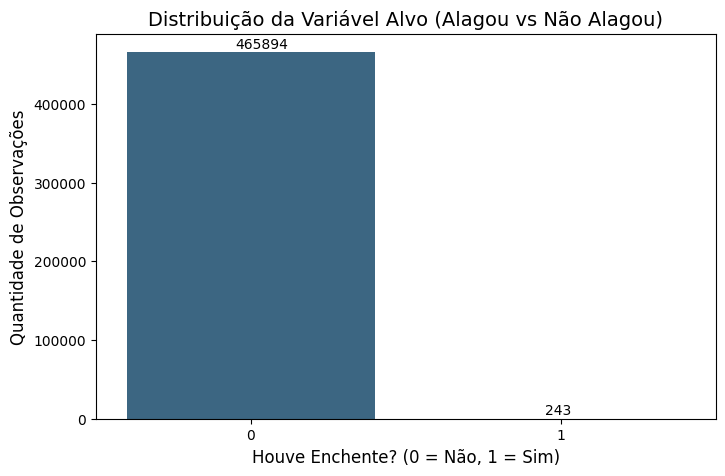

--------------------------------------------------


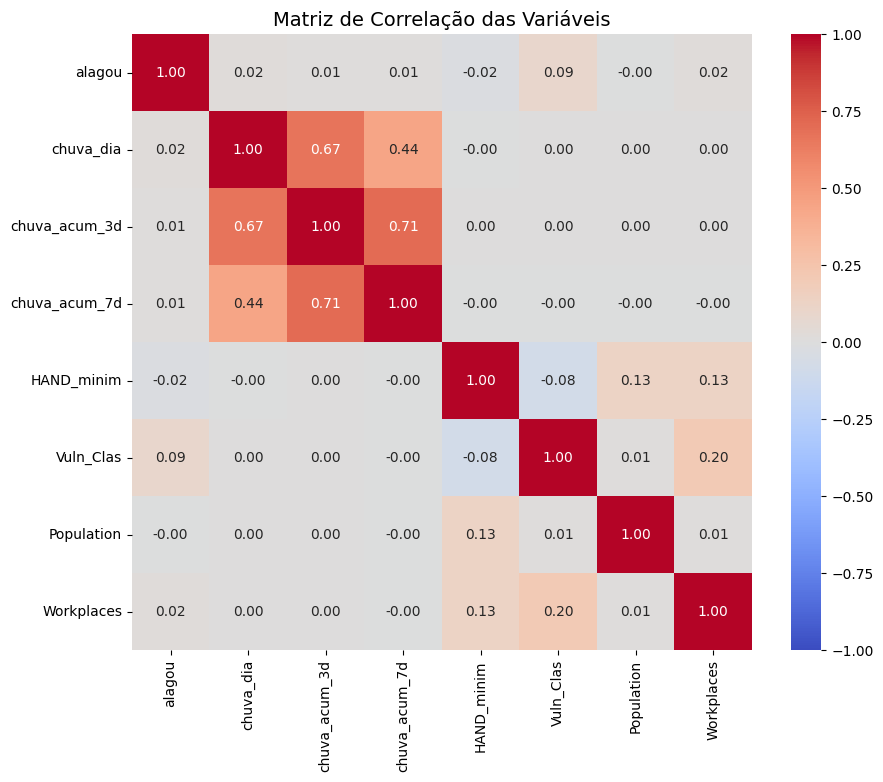

In [ ]:
# 1. Gráfico de Desbalanceamento
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_final, x='alagou', palette='viridis')
plt.title('Distribuição da Variável Alvo (Alagou vs Não Alagou)', fontsize=14)
plt.xlabel('Houve Enchente? (0 = Não, 1 = Sim)', fontsize=12)
plt.ylabel('Quantidade de Observações', fontsize=12)

# Adicionar os números acima das barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + 0.35, p.get_height() + 5000))

plt.show()

print("-" * 50)

# 2. Matriz de Correlação
plt.figure(figsize=(10, 8))
colunas_correlacao = ['alagou', 'chuva_dia', 'chuva_acum_3d', 'chuva_acum_7d',
                      'HAND_minim', 'Vuln_Clas', 'Population', 'Workplaces']
correlacao = df_final[colunas_correlacao].corr()

sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlação das Variáveis', fontsize=14)
plt.show()

# 6. Resultados Preliminares: O Modelo Baseline (Regressão Logística)
Para fechar, rodamos o nosso modelo estatístico base, aplicando o peso balanceado para lidar com as classes minoritárias (as enchentes).

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


=== RELATÓRIO DE CLASSIFICAÇÃO (BASELINE) ===
              precision    recall  f1-score   support

           0       1.00      0.84      0.91    139769
           1       0.00      0.90      0.01        73

    accuracy                           0.84    139842
   macro avg       0.50      0.87      0.46    139842
weighted avg       1.00      0.84      0.91    139842



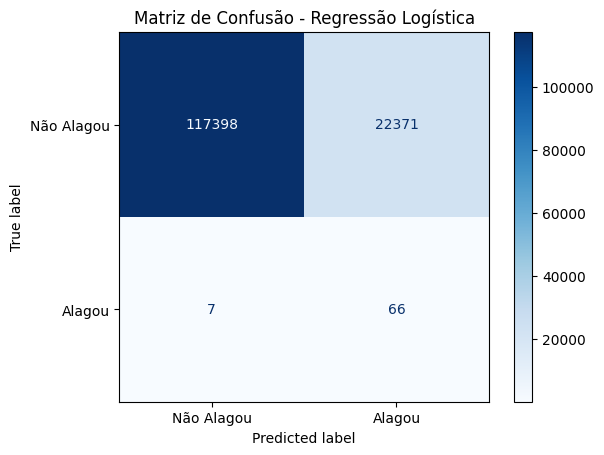

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Separar os previsores (X) e a variável alvo (y)
X = df_final.drop(columns=['GRID_ID', 'Data', 'alagou'])
y = df_final['alagou']

# Divisão Simples 70/30 (Para o relatório preliminar)
# Nota: Na versão final, usaremos Validação Cruzada Espacial como prometido.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Treinar o Modelo Baseline (Com balanceamento de classes)
modelo_base = LogisticRegression(class_weight='balanced', max_iter=1000)
modelo_base.fit(X_train, y_train)

# Fazer Predições
y_pred = modelo_base.predict(X_test)

# Mostrar Resultados
print("=== RELATÓRIO DE CLASSIFICAÇÃO (BASELINE) ===")
print(classification_report(y_test, y_pred))

# Plotar a Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não Alagou', 'Alagou'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

# 7. Treinamento dos Modelos Baseados em Árvores (Interpretáveis)
Nesta etapa, treinamos a Árvore de Decisão e o Random Forest. Ambos lidam muito bem com dados tabulares e desbalanceados sem precisarem de padronização de escala. O hiperparâmetro "class_weight='balanced'" garantirá que a classe 1 (Enchente) tenha um peso muito maior durante o aprendizado.

=== TREINANDO ÁRVORE DE DECISÃO ===
              precision    recall  f1-score   support

           0       1.00      0.95      0.98    139769
           1       0.01      0.77      0.02        73

    accuracy                           0.95    139842
   macro avg       0.50      0.86      0.50    139842
weighted avg       1.00      0.95      0.97    139842



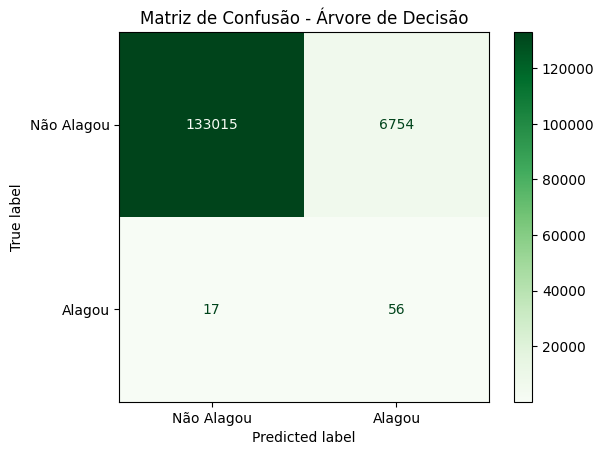


=== TREINANDO RANDOM FOREST ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    139769
           1       0.05      0.47      0.09        73

    accuracy                           0.99    139842
   macro avg       0.52      0.73      0.54    139842
weighted avg       1.00      0.99      1.00    139842



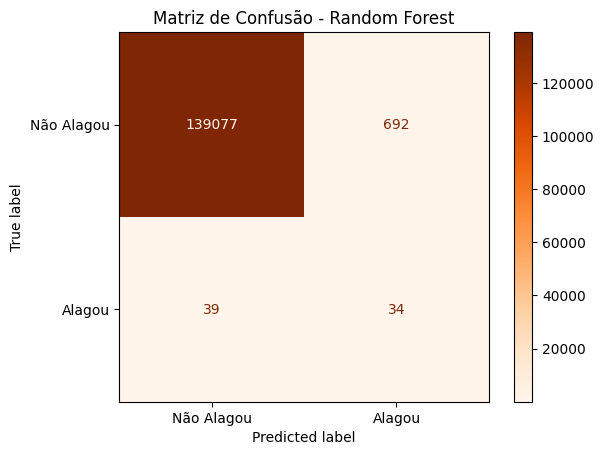

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("=== TREINANDO ÁRVORE DE DECISÃO ===")
# Inicializar e treinar a Árvore
modelo_dt = DecisionTreeClassifier(class_weight='balanced', random_state=42, max_depth=10)
modelo_dt.fit(X_train, y_train)

# Predições e Matriz
y_pred_dt = modelo_dt.predict(X_test)
print(classification_report(y_test, y_pred_dt))

cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Não Alagou', 'Alagou'])
disp_dt.plot(cmap='Greens')
plt.title('Matriz de Confusão - Árvore de Decisão')
plt.show()

print("\n=== TREINANDO RANDOM FOREST ===")
# Inicializar e treinar o Random Forest
modelo_rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100, max_depth=15, n_jobs=-1)
modelo_rf.fit(X_train, y_train)

# Predições e Matriz
y_pred_rf = modelo_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Não Alagou', 'Alagou'])
disp_rf.plot(cmap='Oranges')
plt.title('Matriz de Confusão - Random Forest')
plt.show()

# 8. Treinamento da Rede Neural (MLP)
Como redes neurais (modelos caixa-preta) são sensíveis à escala dos dados, precisamos aplicar o StandardScaler antes do treinamento. Ao contrário dos modelos anteriores, o MLP do Scikit-Learn não possui um parâmetro direto de 'class_weight', o que nos permitirá observar como uma arquitetura complexa lida nativamente com o desbalanceamento.

=== TREINANDO MULTILAYER PERCEPTRON (MLP) ===
Balanceando os dados para a Rede Neural...

=== RELATÓRIO DE CLASSIFICAÇÃO (MLP) ===
              precision    recall  f1-score   support

           0       1.00      0.87      0.93    139769
           1       0.00      0.85      0.01        73

    accuracy                           0.87    139842
   macro avg       0.50      0.86      0.47    139842
weighted avg       1.00      0.87      0.93    139842



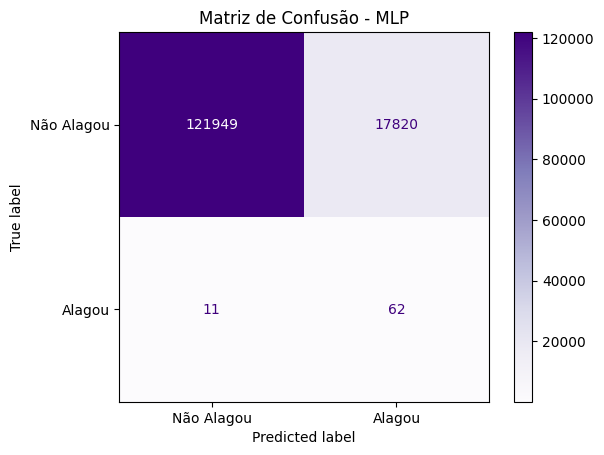

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import RandomUnderSampler

print("=== TREINANDO MULTILAYER PERCEPTRON (MLP) ===")

# 1. Padronizar (escalonar) os dados para a Rede Neural
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Balancear os dados de Treino (já que o MLP não tem class_weight)
print("Balanceando os dados para a Rede Neural...")
rus = RandomUnderSampler(random_state=42)
X_train_bal, y_train_bal = rus.fit_resample(X_train_scaled, y_train)

# 3. Inicializar e treinar o MLP com os dados balanceados
modelo_mlp = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
modelo_mlp.fit(X_train_bal, y_train_bal)

# 4. Predições e Matriz
y_pred_mlp = modelo_mlp.predict(X_test_scaled)
print("\n=== RELATÓRIO DE CLASSIFICAÇÃO (MLP) ===")
print(classification_report(y_test, y_pred_mlp))

cm_mlp = confusion_matrix(y_test, y_pred_mlp)
disp_mlp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=['Não Alagou', 'Alagou'])
disp_mlp.plot(cmap='Purples')
plt.title('Matriz de Confusão - MLP')
plt.show()

# 9. Tabela Comparativa de Resultados
Agora vamos extrair especificamente as métricas da classe 1 (Alagou) de todos os modelos e consolidá-las em um único DataFrame para facilitar a análise e o transporte dos dados para o relatório final no LaTeX.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

def extrair_metricas(y_true, y_pred, nome_modelo):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, pos_label=1, average='binary')
    # Pegar os Falsos Positivos da matriz de confusão para análise da Defesa Civil
    cm = confusion_matrix(y_true, y_pred)
    falsos_positivos = cm[0][1]

    return {
        'Modelo': nome_modelo,
        'Precisão': round(precision, 4),
        'Recall (Sensibilidade)': round(recall, 4),
        'F1-score': round(f1, 4),
        'Alarmes Falsos (Falsos Positivos)': falsos_positivos
    }

# Coletar as métricas de todos os modelos (incluindo a regressão logística da etapa anterior)
resultados = [
    extrair_metricas(y_test, y_pred, 'Regressão Logística (Baseline)'),
    extrair_metricas(y_test, y_pred_dt, 'Árvore de Decisão'),
    extrair_metricas(y_test, y_pred_rf, 'Random Forest'),
    extrair_metricas(y_test, y_pred_mlp, 'MLP (Rede Neural)')
]

df_comparativo = pd.DataFrame(resultados)
display(df_comparativo)

,Modelo,Precisão,Recall (Sensibilidade),F1-score,Alarmes Falsos (Falsos Positivos)
0,Regressão Logística (Baseline),0.0029,0.9041,0.0059,22371
1,Árvore de Decisão,0.0082,0.7671,0.0163,6754
2,Random Forest,0.0468,0.4658,0.0851,692
3,MLP (Rede Neural),0.0035,0.8493,0.0069,17820


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve

# --- helper: escolhe o limiar que maximiza o F1 da classe 1 ---
def melhor_limiar(y_true, probas):
    prec, rec, thr = precision_recall_curve(y_true, probas)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    i = f1[:-1].argmax()          # thr tem tamanho len-1
    return thr[i], f1[i]

# ========== 1) REGRESSÃO LOGÍSTICA (com escala + limiar) ==========
lr = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight='balanced', max_iter=2000))
lr.fit(X_train, y_train)
p_lr = lr.predict_proba(X_test)[:, 1]
thr_lr, _ = melhor_limiar(y_test, p_lr)
y_pred_lr_opt = (p_lr >= thr_lr).astype(int)
print(f"[LR]  limiar ótimo = {thr_lr:.3f}")

# ========== 2) ÁRVORE (grid de hiperparâmetros + limiar) ==========
param = {'max_depth': [6, 8, 10, 12, 15],
         'min_samples_leaf': [5, 10, 20, 50]}
gs = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param, scoring='f1', cv=3, n_jobs=-1)
gs.fit(X_train, y_train)
dt = gs.best_estimator_
print(f"[Árvore] melhores params = {gs.best_params_}")

p_dt = dt.predict_proba(X_test)[:, 1]
thr_dt, _ = melhor_limiar(y_test, p_dt)
y_pred_dt_opt = (p_dt >= thr_dt).astype(int)
print(f"[Árvore] limiar ótimo = {thr_dt:.3f}")

# ========== Comparativo final ==========
resultados_opt = [
    extrair_metricas(y_test, y_pred_lr_opt, 'Regressão Logística (escala+limiar)'),
    extrair_metricas(y_test, y_pred_dt_opt, 'Árvore de Decisão (tunada+limiar)'),
]
df_opt = pd.DataFrame(resultados_opt)
display(df_opt)


[LR]  limiar ótimo = 0.998
[Árvore] melhores params = {'max_depth': 15, 'min_samples_leaf': 5}
[Árvore] limiar ótimo = 0.981


,Modelo,Precisão,Recall (Sensibilidade),F1-score,Alarmes Falsos (Falsos Positivos)
0,Regressão Logística (escala+limiar),0.0380,0.0822,0.0519,152
1,Árvore de Decisão (tunada+limiar),0.0241,0.5753,0.0463,1698


In [ ]:
import geopandas as gpd
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_curve, confusion_matrix

# 1) Atribui um distrito a cada célula (centroide dentro do polígono do distrito)
distritos = gpd.read_file("/content/floods_data/floods_saopaulo-main/4_auxilary/Districts.shp").to_crs(grid.crs)
grid_cent = grid[['GRID_ID', 'geometry']].copy()
grid_cent['geometry'] = grid_cent.geometry.centroid
cell_dist = gpd.sjoin(grid_cent, distritos[['ds_nome', 'geometry']], how='left', predicate='within')
mapa_dist = cell_dist.drop_duplicates('GRID_ID').set_index('GRID_ID')['ds_nome']

df_cv = df_final.copy()
df_cv['Distrito'] = df_cv['GRID_ID'].map(mapa_dist)
df_cv = df_cv.dropna(subset=['Distrito'])         # descarta células sem distrito

X_cv   = df_cv.drop(columns=['GRID_ID', 'Data', 'alagou', 'Distrito'])
y_cv   = df_cv['alagou'].values
grupos = df_cv['Distrito'].values
print(f"Distritos: {df_cv['Distrito'].nunique()} | observações: {len(df_cv)}")

# 2) Validação Cruzada Espacial: GroupKFold por distrito
gkf = GroupKFold(n_splits=5)
oof_prob = np.zeros(len(y_cv))                    # probabilidades fora-da-amostra

params = gs.best_params_ if 'gs' in globals() else {'max_depth': 10, 'min_samples_leaf': 20}
for tr, te in gkf.split(X_cv, y_cv, groups=grupos):
    modelo = DecisionTreeClassifier(class_weight='balanced', random_state=42, **params)
    modelo.fit(X_cv.iloc[tr], y_cv[tr])
    oof_prob[te] = modelo.predict_proba(X_cv.iloc[te])[:, 1]

# 3) Limiar global escolhido nas predições held-out (não usa treino)
prec, rec, thr = precision_recall_curve(y_cv, oof_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
i = f1[:-1].argmax()
limiar = thr[i]
y_oof = (oof_prob >= limiar).astype(int)

cm = confusion_matrix(y_cv, y_oof)
print(f"Árvore de Decisão — Validação Cruzada Espacial (por distrito) ===")
print(f"Limiar (OOF)      = {limiar:.3f}")
print(f"Precisão          = {prec[i]:.4f}")
print(f"Recall            = {rec[i]:.4f}")
print(f"F1-score          = {f1[i]:.4f}")
print(f"Falsos positivos  = {cm[0,1]}")
print(f"""Matriz de confusão:
{cm}""")



Distritos: 25 | observações: 451792
Árvore de Decisão — Validação Cruzada Espacial (por distrito) ===
Limiar (OOF)      = 0.989
Precisão          = 0.0416
Recall            = 0.0785
F1-score          = 0.0544
Falsos positivos  = 438
Matriz de confusão:
[[451112    438]
 [   223     19]]


In [ ]:
import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import precision_recall_curve, confusion_matrix

base = df_final.drop(columns=['GRID_ID','Data','alagou']).select_dtypes(include=[np.number]).copy()
y = df_final['alagou'].values

eps = 1.0
if 'HAND_minim' in base:
    base['chuva_sobre_hand'] = base['chuva_dia'] / (base['HAND_minim'] + eps)
    if 'chuva_max_h' in base:
        base['chuvamax_sobre_hand'] = base['chuva_max_h'] / (base['HAND_minim'] + eps)
    base['hand_baixo'] = (base['HAND_minim'] < 3).astype(int)
if 'Vuln_Clas' in base and 'chuva_acum_3d' in base:
    base['chuva3d_x_vuln'] = base['chuva_acum_3d'] * base['Vuln_Clas']
for c in ['chuva_dia','chuva_max_h','chuva_acum_3d','chuva_acum_7d','radiacao_sum']:
    if c in base: base['log_'+c] = np.log1p(base[c].clip(lower=0))

X = base.values
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# subamostra só para a BUSCA de hiperparâmetros (acelera muito)
rng = np.random.RandomState(42)
pos = np.where(y==1)[0]; neg = np.where(y==0)[0]
idx = np.concatenate([pos, rng.choice(neg, size=min(len(neg),40000), replace=False)])

pipe = Pipeline([('sc', StandardScaler()),
                 ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, solver='liblinear'))])
grid = {'clf__penalty': ['l1','l2'], 'clf__C': [0.1, 1, 5]}
gs = GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1)
gs.fit(X[idx], y[idx])
print("Melhores params LR:", gs.best_params_)

# F1 final: validação cruzada no conjunto COMPLETO com os melhores params
proba = cross_val_predict(gs.best_estimator_, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:,1]
prec, rec, thr = precision_recall_curve(y, proba)
f1 = 2*prec*rec/(prec+rec+1e-9); i = f1[:-1].argmax(); lim = thr[i]
cm = confusion_matrix(y, (proba>=lim).astype(int))
print(f"""
=== REGRESSÃO LOGÍSTICA (otimizada) ===""")
print(f"Limiar={lim:.3f} | Precisão={prec[i]:.4f} | Recall={rec[i]:.4f} | F1={f1[i]:.4f} | FP={cm[0,1]}")
print(cm)

Melhores params LR: {'clf__C': 1, 'clf__penalty': 'l2'}

=== REGRESSÃO LOGÍSTICA (otimizada) ===
Limiar=0.997 | Precisão=0.0457 | Recall=0.1687 | F1=0.0719 | FP=857
[[465037    857]
 [   202     41]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier

X = df_final.drop(columns=['GRID_ID','Data','alagou']).select_dtypes(include=[np.number]).values
y = df_final['alagou'].values
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rng = np.random.RandomState(42)
pos = np.where(y==1)[0]; neg = np.where(y==0)[0]
idx = np.concatenate([pos, rng.choice(neg, size=min(len(neg),40000), replace=False)])

grid_dt = {'max_depth':[10, 16, None], 'min_samples_leaf':[5, 20, 50], 'ccp_alpha':[0.0, 1e-4]}
gs_dt = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                     grid_dt, scoring='f1', cv=cv, n_jobs=-1)
gs_dt.fit(X[idx], y[idx])
print("Melhores params Árvore:", gs_dt.best_params_)

proba = cross_val_predict(gs_dt.best_estimator_, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:,1]
prec, rec, thr = precision_recall_curve(y, proba)
f1 = 2*prec*rec/(prec+rec+1e-9); i = f1[:-1].argmax(); lim = thr[i]
cm = confusion_matrix(y, (proba>=lim).astype(int))
print(f"""
=== ÁRVORE DE DECISÃO (otimizada) ===""")
print(f"Limiar={lim:.3f} | Precisão={prec[i]:.4f} | Recall={rec[i]:.4f} | F1={f1[i]:.4f} | FP={cm[0,1]}")
print(cm)

Melhores params Árvore: {'ccp_alpha': 0.0001, 'max_depth': None, 'min_samples_leaf': 5}

=== ÁRVORE DE DECISÃO (otimizada) ===
Limiar=0.992 | Precisão=0.0520 | Recall=0.3333 | F1=0.0900 | FP=1476
[[464418   1476]
 [   162     81]]
